# 1조 신용위험 분류 및 우량고객 선정 최종 제출본

이 노트북은 이번 최종 모델 구성을 기준으로 두 분석을 한 파일에 통합한다.

1. **신용위험 분류:** RBF-SVC로 Good/Bad를 예측하고 독립 테스트셋 및 반복 분할로 성능을 검증한다.
2. **우량고객 선정:** 분류 임계값과 분리해 계좌 자격을 먼저 적용하고, 신용위험과 고객가치를 각각 계산한 뒤 최종 VIP를 선정한다.

분류 성능과 VIP 선정은 목적이 다르므로 같은 점수나 임계값을 공유하지 않는다. SVC는 Good/Bad 분류 성능을 평가하고, VIP 분석은 금융 변수 중심의 설명 가능한 위험점수와 고객가치를 결합한다.


# Part 1. RBF-SVC 신용위험 분류

- 학습 데이터 800명을 학습 640명·테스트 160명으로 계층 분할한다.
- `C=0.1`, `gamma=0.03`의 RBF-SVC를 사용한다.
- 판정 임계값은 학습 640명 내부의 5-fold OOF 순위에서만 결정한다.
- 테스트 160명은 임계값 결정에 사용하지 않고 최종 성능 평가에만 사용한다.


## 1. 환경 설정 및 파일 업로드

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import rankdata
from joblib import Parallel, delayed

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                             confusion_matrix, classification_report)

C, GAMMA = 0.1, 0.03
SPLIT_SEED = 42
THR_SEEDS = list(range(1, 31))
TRAIN_NAME = '분류 학습 데이터셋.csv'

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

search_bases = [Path.cwd(), *Path.cwd().parents]
train_candidates = []
for base in search_bases:
    train_candidates.extend([base / TRAIN_NAME, base / '분류_학습_데이터셋.csv'])
train_candidates.append(Path('/content') / TRAIN_NAME)
TRAIN_PATH = next((p for p in train_candidates if p.exists()), None)
if TRAIN_PATH is None and IN_COLAB:
    print('학습 데이터 CSV를 선택하세요:', TRAIN_NAME)
    uploaded = files.upload()
    TRAIN_PATH = Path(next(iter(uploaded)))
assert TRAIN_PATH is not None, '학습 데이터 CSV를 찾지 못했어.'

raw = pd.read_csv(TRAIN_PATH, index_col=0)
y_all = (raw['Risk'] == 'bad').astype(int).to_numpy()
print('불러온 파일:', TRAIN_PATH, raw.shape)

불러온 파일: C:\Users\leeyo\Downloads\IBA\Restricted-Area\IBA\분류프로젝트\분류_학습_데이터셋.csv (800, 10)


## 2. 전처리
| 변수 | 처리 |
|---|---|
| Sex, Housing, Purpose, Job | 원핫 인코딩 |
| Saving | little 1 / moderate 2 / 결측 3 / quite rich 4 / rich 5 |
| Checking | little 1 / moderate 2 / rich 3 / 결측 4 |
| Saving_missing, Checking_missing | 결측이면 1 |
| log(Credit amount / Duration) | 파생 변수 |
| 수치 변수 전부 | StandardScaler (Pipeline 안에서 학습 데이터에만 fit) |

In [2]:
NOMINAL = ['Sex', 'Housing', 'Purpose', 'Job']
NUMERIC = ['Age', 'Credit amount', 'Duration', 'sav_rank', 'chk_rank',
           'Saving_missing', 'Checking_missing', 'log_amt_dur']
SAV_RANK = {'little': 1, 'moderate': 2, 'quite rich': 4, 'rich': 5}   # 결측 = 3
CHK_RANK = {'little': 1, 'moderate': 2, 'rich': 3}                    # 결측 = 4

def build_features(df):
    f = df[NOMINAL + ['Age', 'Credit amount', 'Duration']].copy()
    f['Job'] = f['Job'].astype(str)
    f['sav_rank'] = df['Saving accounts'].map(SAV_RANK).fillna(3)
    f['chk_rank'] = df['Checking account'].map(CHK_RANK).fillna(4)
    f['Saving_missing'] = df['Saving accounts'].isna().astype(int)
    f['Checking_missing'] = df['Checking account'].isna().astype(int)
    f['log_amt_dur'] = np.log(df['Credit amount'] / df['Duration'])
    return f[NOMINAL + NUMERIC]

def make_model():
    encoder = ColumnTransformer([
        ('nominal', OneHotEncoder(handle_unknown='ignore'), NOMINAL),
        ('numeric', StandardScaler(), NUMERIC),
    ])
    return Pipeline([('encoder', encoder),
                     ('svc', SVC(kernel='rbf', C=C, gamma=GAMMA, random_state=42))])

X_all = build_features(raw)

## 3. 학습 640 / 테스트 160 분할

In [3]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=SPLIT_SEED)
print(f'학습 {len(y_tr)}개 (bad {y_tr.sum()}) | 테스트 {len(y_te)}개 (bad {y_te.sum()})')

학습 640개 (bad 192) | 테스트 160개 (bad 48)


## 4. 임계값 결정 (학습 640개 안에서만)
640개를 5-fold로 나눠 OOF 순위 점수를 만들고, F1이 최대가 되는 순위 임계값을 구해. seed 30개로 반복해서 평균을 써.

In [4]:
THRESHOLD_GRID = np.arange(0.02, 0.99, 0.005)

def pick_threshold(ranks, y_true):
    cand = np.unique(np.quantile(ranks, THRESHOLD_GRID))
    pred = ranks[:, None] >= cand[None, :]
    tp = np.count_nonzero(pred & (y_true[:, None] == 1), axis=0)
    return float(cand[np.argmax(2 * tp / (pred.sum(axis=0) + y_true.sum()))])

def oof_threshold(seed, X, y):
    oof = np.zeros(len(y))
    for a, b in StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y):
        m = make_model().fit(X.iloc[a], y[a])
        oof[b] = rankdata(m.decision_function(X.iloc[b])) / len(b)
    return pick_threshold(oof, y)

thr = np.array(Parallel(n_jobs=-1)(delayed(oof_threshold)(s, X_tr, y_tr) for s in THR_SEEDS))
THRESHOLD = float(thr.mean())
print(f'임계값 {THRESHOLD:.4f} ± {thr.std():.4f} → 위험도 상위 {(1 - THRESHOLD) * 100:.1f}%를 bad로 판정')

임계값 0.5796 ± 0.0342 → 위험도 상위 42.0%를 bad로 판정


## 5. 640개로 학습 → 테스트 160개 평가

In [5]:
model = make_model().fit(X_tr, y_tr)
ranks = rankdata(model.decision_function(X_te)) / len(X_te)
pred = (ranks >= THRESHOLD).astype(int)

print('=' * 50)
print(f'  테스트 160개 | F1 (bad) : {f1_score(y_te, pred):.4f}')
print('=' * 50)
print(f'  Precision : {precision_score(y_te, pred):.4f}')
print(f'  Recall    : {recall_score(y_te, pred):.4f}')
print(f'  Accuracy  : {accuracy_score(y_te, pred):.4f}')
print()
cm = pd.DataFrame(confusion_matrix(y_te, pred),
                  index=['실제 good', '실제 bad'], columns=['예측 good', '예측 bad'])
display(cm) if 'display' in globals() else print(cm)
print(classification_report(y_te, pred, target_names=['good', 'bad'], digits=3))

  테스트 160개 | F1 (bad) : 0.6034
  Precision : 0.5147
  Recall    : 0.7292
  Accuracy  : 0.7125

         예측 good  예측 bad
실제 good       79      33
실제 bad        13      35
              precision    recall  f1-score   support

        good      0.859     0.705     0.775       112
         bad      0.515     0.729     0.603        48

    accuracy                          0.713       160
   macro avg      0.687     0.717     0.689       160
weighted avg      0.755     0.713     0.723       160



## 6. (참고) 분할을 바꿔가며 반복
테스트셋이 160개(bad 48개)로 작아서 분할에 따라 F1이 크게 흔들려. 분할 seed 20개로 같은 절차를 반복해서 범위를 확인해. 1~2분 정도 걸려.

In [6]:
def holdout_f1(split_seed):
    Xa, Xb, ya, yb = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=split_seed)
    T = np.mean([oof_threshold(s, Xa, ya) for s in THR_SEEDS])
    m = make_model().fit(Xa, ya)
    return f1_score(yb, (rankdata(m.decision_function(Xb)) / len(Xb) >= T).astype(int))

fs = np.array(Parallel(n_jobs=-1)(delayed(holdout_f1)(s) for s in range(100, 120)))
print(f'분할 20번: F1 평균 {fs.mean():.4f} ± {fs.std():.4f} | 범위 {fs.min():.4f} ~ {fs.max():.4f}')

분할 20번: F1 평균 0.5863 ± 0.0399 | 범위 0.5133 ~ 0.6783


## 7. 발표 대표 성능 — 20개 시드 × 5-fold

발표 수치와 코드 결과를 직접 연결하기 위해 최종 SVC 설정을 20개 시드의 5-fold로 평가한다. 각 fold의 학습 데이터에서만 순위 임계값을 선택하고, 해당 fold의 검증 데이터에서 Bad F1을 계산한다.


In [7]:
CV_SEEDS_SVC = list(range(1, 21))

def evaluate_svc_cv(seed):
    rows = []
    cv = StratifiedKFold(5, shuffle=True, random_state=seed)
    for fold, (train_idx, valid_idx) in enumerate(cv.split(X_all, y_all), 1):
        fold_model = make_model().fit(X_all.iloc[train_idx], y_all[train_idx])
        train_rank = rankdata(fold_model.decision_function(X_all.iloc[train_idx])) / len(train_idx)
        valid_rank = rankdata(fold_model.decision_function(X_all.iloc[valid_idx])) / len(valid_idx)
        fold_threshold = pick_threshold(train_rank, y_all[train_idx])
        fold_pred = (valid_rank >= fold_threshold).astype(int)
        rows.append({'시드':seed, 'fold':fold,
                     'Bad F1':f1_score(y_all[valid_idx], fold_pred)})
    return rows

svc_cv_rows = Parallel(n_jobs=-1)(delayed(evaluate_svc_cv)(seed) for seed in CV_SEEDS_SVC)
svc_cv_detail = pd.DataFrame([row for rows in svc_cv_rows for row in rows])
svc_seed_f1 = svc_cv_detail.groupby('시드')['Bad F1'].mean()
print('20개 시드 × 5-fold Bad F1')
print(f'평균 {svc_seed_f1.mean():.4f} ± {svc_seed_f1.std(ddof=0):.4f}')
print(f'범위 {svc_seed_f1.min():.4f} ~ {svc_seed_f1.max():.4f}')


20개 시드 × 5-fold Bad F1
평균 0.5906 ± 0.0086
범위 0.5732 ~ 0.6147


## 8. 전체 800명 학습 및 정답 입력 데이터 200명 예측

학습 데이터 800명 전체로 최종 모델을 적합한다. 판정 임계값은 800명 내부의 30개 시드 OOF 순위로 정하고, 정답 입력 데이터 200명의 `Risk`를 메모리에서 채운다. 별도 CSV는 생성하지 않는다.


In [8]:
ANSWER_NAMES = ['정답 입력 데이터.csv', '정답_입력_데이터.csv', '정답데이터.csv']
answer_candidates = []
for base in [Path.cwd(), *Path.cwd().parents, Path('/content')]:
    answer_candidates.extend(base / name for name in ANSWER_NAMES)
ANSWER_PATH = next((p for p in answer_candidates if p.exists()), None)
if ANSWER_PATH is None and IN_COLAB:
    print('정답 입력 데이터 CSV를 선택하세요.')
    uploaded = files.upload()
    ANSWER_PATH = Path(next(iter(uploaded)))
assert ANSWER_PATH is not None, '정답 입력 데이터 CSV를 찾지 못했습니다.'

svc_answer = pd.read_csv(ANSWER_PATH, index_col=0)
X_answer_svc = build_features(svc_answer)
full_thresholds = np.array(Parallel(n_jobs=-1)(
    delayed(oof_threshold)(seed, X_all, y_all) for seed in THR_SEEDS
))
FULL_THRESHOLD = float(full_thresholds.mean())
svc_final_model = make_model().fit(X_all, y_all)
answer_rank = rankdata(svc_final_model.decision_function(X_answer_svc)) / len(X_answer_svc)
answer_pred = (answer_rank >= FULL_THRESHOLD).astype(int)
svc_answer_filled = svc_answer.copy()
svc_answer_filled['Risk'] = np.where(answer_pred == 1, 'bad', 'good')

print('전체 학습 OOF 평균 임계값:', f'{FULL_THRESHOLD:.4f}')
print('예측 대상:', len(svc_answer_filled), '명')
print(svc_answer_filled['Risk'].value_counts().to_string())
display(svc_answer_filled.head())


전체 학습 OOF 평균 임계값: 0.5659
예측 대상: 200 명
Risk
good    113
bad      87


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
320,28,male,3,own,little,moderate,4249,30,car,bad
326,49,male,2,rent,NaN,NaN,5801,12,furniture/equipment,good
942,31,male,2,own,NaN,NaN,929,24,furniture/equipment,good
584,52,female,3,free,NaN,NaN,2133,12,car,good
138,35,male,2,own,NaN,moderate,2728,15,radio/TV,good


# Part 2. 신용위험과 고객가치를 분리한 VIP 분석

정답 입력 데이터 200명에서 다음 고객은 VIP 평가 전에 제외한다.

- Saving과 Checking이 모두 결측인 고객
- `Saving=little, Checking=NaN` 또는 그 대칭인 `Saving=NaN, Checking=little` 고객

`little + little` 및 `little + 실제 계좌` 조합과 `moderate/quite rich/rich + NaN` 조합은 유지한다. 위험모델과 고객가치의 역할은 분리하며, 기존 WoE 위험모델로 계산한 예상 Bad 확률이 위험 허용 경계 이하인 고객에게만 종합점수와 VVIP/VIP 등급을 적용한다.

In [9]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.optimize import minimize
from scipy.special import expit
from scipy.stats import rankdata
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import StratifiedKFold
from matplotlib import font_manager

VIP_RANDOM_STATE = 42
VIP_N_SPLITS = 5
VIP_CV_SEEDS = list(range(1, 21))
MAX_RISK_ACCEPTANCE = 0.50

# 위험모델에서는 간격이 아닌 상태 순서만 사용한다.
ACCOUNT_ORDER = {'little':1, 'moderate':2, 'quite rich':3, 'rich':4}
# 고객가치용 정책점수는 위험모델과 분리한다.
ACCOUNT_VALUE = {'little':0.25, 'moderate':0.50, 'quite rich':0.75, 'rich':1.0}
MISSING_LABEL = '__missing__'

plt.style.use('seaborn-v0_8-whitegrid')
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
for font_name in ['NanumGothic', 'Noto Sans CJK KR', 'Malgun Gothic', 'AppleGothic']:
    if font_name in available_fonts:
        plt.rcParams['font.family'] = font_name
        break
else:
    plt.rcParams['font.family'] = 'DejaVu Sans'
    print('한글 글꼴이 없습니다. Colab에서는 NanumGothic 설치 후 다시 실행하세요.')
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_columns', 100)

TRAIN_NAMES = ['분류_학습_데이터셋.csv', '분류 학습 데이터셋.csv']
ANSWER_NAMES_VIP = ['정답 입력 데이터.csv', '정답_입력_데이터.csv', '정답데이터.csv']

def find_data_file(names):
    candidates = []
    for base in [Path.cwd(), *Path.cwd().parents, Path('/content')]:
        candidates.extend(base / name for name in names)
    return next((p for p in candidates if p.exists()), None)

vip_train_path = find_data_file(TRAIN_NAMES)
vip_answer_path = find_data_file(ANSWER_NAMES_VIP)
if (vip_train_path is None or vip_answer_path is None) and IN_COLAB:
    print('학습 데이터와 정답 입력 데이터 CSV를 업로드하세요.')
    uploaded = files.upload()
    vip_train_path = vip_train_path or next((Path(name) for name in uploaded if name in TRAIN_NAMES), None)
    vip_answer_path = vip_answer_path or next((Path(name) for name in uploaded if name in ANSWER_NAMES_VIP), None)
assert vip_train_path is not None and vip_answer_path is not None, 'VIP 분석용 데이터 파일을 찾지 못했습니다.'

vip_train_all = pd.read_csv(vip_train_path, index_col=0)
vip_answer_all = pd.read_csv(vip_answer_path, index_col=0)
print('전체 학습 데이터:', vip_train_all.shape, '| 전체 후보:', vip_answer_all.shape)


mkdir -p failed for path C:\Users\leeyo\AppData\Local\matplotlib: [WinError 5] 액세스가 거부되었습니다: 'C:\\Users\\leeyo\\AppData\\Local\\matplotlib'


Matplotlib created a temporary cache directory at C:\Users\leeyo\AppData\Local\Temp\matplotlib-5xowloks because there was an issue with the default path (C:\Users\leeyo\AppData\Local\matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


전체 학습 데이터: (800, 10) | 전체 후보: (200, 10)


## 1. 계좌 자격과 결측 처리

- 두 계좌가 모두 없는 고객과 양방향 `little + NaN` 조합을 완전히 제외한다.
- 계좌 미보유(`NaN`)는 계좌가치 0, `little`은 0.25로 서로 다르게 처리한다.
- `little + little`, `little + moderate/quite rich/rich`, `moderate/quite rich/rich + NaN`은 유지한다.
- 위험모델에서는 결측을 독립 범주로 두고, 실제 계좌 상태에만 단조 제약을 적용한다.

In [10]:
def add_vip_features(df):
    out = df.copy()
    out['saving_state'] = out['Saving accounts'].fillna(MISSING_LABEL)
    out['checking_state'] = out['Checking account'].fillna(MISSING_LABEL)
    out['saving_exists'] = out['Saving accounts'].notna().astype(int)
    out['checking_exists'] = out['Checking account'].notna().astype(int)
    out['account_count'] = out['saving_exists'] + out['checking_exists']
    out['saving_value'] = out['Saving accounts'].map(ACCOUNT_VALUE).fillna(0.0)
    out['checking_value'] = out['Checking account'].map(ACCOUNT_VALUE).fillna(0.0)
    out['account_value'] = (out['saving_value'] + out['checking_value']) / 2
    return out

vip_train_features = add_vip_features(vip_train_all)
vip_answer_features = add_vip_features(vip_answer_all)
vip_train = vip_train_features[vip_train_features['account_count'].ge(1)].copy()

both_missing = vip_answer_features['Saving accounts'].isna() & vip_answer_features['Checking account'].isna()
little_nan = (
    (vip_answer_features['Saving accounts'].eq('little') & vip_answer_features['Checking account'].isna())
    | (vip_answer_features['Saving accounts'].isna() & vip_answer_features['Checking account'].eq('little'))
)
vip_eligible = ~(both_missing | little_nan)
vip_candidates = vip_answer_features.loc[vip_eligible].copy()
vip_excluded = vip_answer_features.loc[~vip_eligible].copy()
vip_y = vip_train['Risk'].eq('bad').astype(int).to_numpy()

exclusion_summary = pd.DataFrame({
    '구분': ['전체 후보', '두 계좌 모두 없어 제외', 'little + NaN 제외', '최종 평가 후보'],
    '고객 수': [len(vip_answer_features), int(both_missing.sum()), int(little_nan.sum()), len(vip_candidates)]
})
display(exclusion_summary)

rate_rows = []
for source, state_col in [('Saving accounts','saving_state'),('Checking account','checking_state')]:
    temp = vip_train.assign(상태=vip_train[state_col].replace(MISSING_LABEL, '결측'))
    table = temp.groupby('상태')['Risk'].agg(고객수='size', Bad_비율=lambda s:s.eq('bad').mean()).reset_index()
    table.insert(0, '계좌', source)
    rate_rows.append(table)
display(pd.concat(rate_rows, ignore_index=True).style.format({'Bad_비율':'{:.1%}'}))

,구분,고객 수
0,전체 후보,200
1,두 계좌 모두 없어 제외,26
2,little + NaN 제외,40
3,최종 평가 후보,134


,계좌,상태,고객수,Bad_비율
0,Saving accounts,little,477,35.4%
1,Saving accounts,moderate,86,32.6%
2,Saving accounts,quite rich,53,17.0%
3,Saving accounts,rich,40,12.5%
4,Saving accounts,결측,71,29.6%
5,Checking account,little,216,48.6%
6,Checking account,moderate,218,38.5%
7,Checking account,rich,53,26.4%
8,Checking account,결측,240,12.1%


## 2. 데이터 기반 단조 WoE 위험모델

Credit amount와 Duration은 분위 구간의 실제 Bad 비율을 사용하고, 임의 정책 배수나 강제 계수 하한을 적용하지 않는다. 계좌 결측은 독립 WoE로 계산하며, 보유 계좌 상태에만 품질이 좋아질수록 위험도가 높아지지 않는 단조 제약을 적용한다.


### WoE, 신용안정성, 고객가치 및 종합점수 계산식

각 구간 $j$의 WoE는 해당 구간의 Bad 확률을 오즈로 바꾼 뒤 로그를 취한다.

$$WoE_j = \log\left(\frac{p_{Bad,j}}{1-p_{Bad,j}}\right)$$

기존 WoE 로지스틱 모형의 선형점수와 예상 Bad 확률은 다음과 같다.

$$z = \beta_0 + \sum_j \beta_j \times WoE_j$$

$$P(Bad) = \frac{1}{1+\exp(-z)}$$

새 모델을 학습하지 않고 위 예상 Bad 확률을 그대로 변환해 신용안정성점수를 계산한다.

$$\text{신용안정성점수} = 1-P(Bad)$$

고객가치의 내부 가중치는 대출거래가치 30%, 계좌관계가치 70%로 고정한다.

$$\text{고객가치점수} = 0.30 \times \text{대출거래가치} + 0.70 \times \text{계좌관계가치}$$

위험 허용 경계를 통과한 고객에게만 최종 종합점수를 계산한다.

$$\text{종합점수} = 0.60 \times \text{신용안정성점수} + 0.40 \times \text{고객가치점수}$$

신용안정성점수와 고객가치점수는 모두 0~1 범위이며, 값이 클수록 우수하다. 위험 경계를 통과하지 못한 고객은 종합점수를 부여하지 않고 무조건 일반으로 분류한다.

### 점수별 계산 및 도출 과정

아래 네 점수는 모두 같은 방향, 즉 **값이 클수록 우수**하도록 구성한다. 단, 예상 Bad 확률은 값이 작을수록 안전하다.

#### 1. 예상 Bad 확률

먼저 고객의 `Credit amount`, `Duration`, `Saving accounts`, `Checking account`를 학습 데이터에서 정한 구간으로 변환한다. 각 구간 $j$의 평활 Bad 비율 $p_{Bad,j}$로 WoE를 계산한다.

$$
WoE_j=\log\left(\frac{p_{Bad,j}}{1-p_{Bad,j}}\right)
$$

고객이 속한 각 변수 구간의 WoE에 기존 WoE 로지스틱 모형의 계수 $\beta_j$를 곱하고 절편 $\beta_0$를 더해 선형 위험점수 $z$를 구한다.

$$
z=\beta_0+\sum_j \beta_j WoE_j
$$

이를 로지스틱 함수로 변환한 값이 해당 고객의 예상 Bad 확률이다.

$$
\text{예상 Bad 확률}=P(Bad)=\frac{1}{1+\exp(-z)}
$$

코드에서는 `expit(score_vip_scorecard(...))`로 계산해 `예상_Bad_확률` 열에 저장한다.

#### 2. 신용안정성점수

신용안정성점수는 새 모델을 학습해 만드는 값이 아니라, 위에서 구한 예상 Bad 확률의 반대 방향 점수이다.

$$
\text{신용안정성점수}=1-\text{예상 Bad 확률}
$$

예를 들어 예상 Bad 확률이 0.20이면 신용안정성점수는 $1-0.20=0.80$이다. 결과는 `신용안정성_점수` 열에 저장하며 0~1 범위에서 클수록 안전하다.

#### 3. 고객가치점수

대출거래가치는 대출금액의 백분위 순위와 대출기간의 백분위 순위를 평균하여 계산한다.

$$
\text{대출거래가치}
=\frac{\text{대출금액 백분위 순위}+\text{대출기간 백분위 순위}}{2}
$$

계좌별 가치는 `NaN=0`, `little=0.25`, `moderate=0.50`, `quite rich=0.75`, `rich=1.00`으로 변환한다. Saving과 Checking의 평균이 계좌관계가치이다.

$$
\text{계좌관계가치}
=\frac{\text{Saving 계좌가치}+\text{Checking 계좌가치}}{2}
$$

두 구성요소에 고정 정책 가중치 30%와 70%를 적용한다.

$$
\text{고객가치점수}
=0.30\times\text{대출거래가치}
+0.70\times\text{계좌관계가치}
$$

결과는 `고객가치_점수` 열에 저장하며 0~1 범위에서 클수록 고객가치가 높다.

#### 4. 종합점수

먼저 예상 Bad 확률이 교차검증으로 정한 위험 허용 경계 이하인지 검사한다.

$$
\text{위험기준 통과}
=\mathbf{1}\left(\text{예상 Bad 확률}\leq\text{위험 허용 경계}\right)
$$

위험기준을 통과한 고객에게만 신용안정성 60%, 고객가치 40%를 적용해 종합점수를 계산한다.

$$
\text{종합점수}
=0.60\times\text{신용안정성점수}
+0.40\times\text{고객가치점수}
$$

위험기준 미통과자의 `종합_VIP_점수`는 결측값(`NaN`)으로 유지하며 무조건 일반으로 분류한다. 통과자는 종합점수 0.80 이상이면 VVIP, 0.60 이상 0.80 미만이면 VIP, 0.60 미만이면 일반이다.

In [11]:
VIP_FEATURES = ['Credit amount','Duration','saving_state','checking_state']
VIP_NUMERIC = ['Credit amount','Duration']
VIP_ACCOUNT = ['saving_state','checking_state']

def smooth_bad_rate(bad, total, global_rate, strength=8.0):
    return (bad + strength*global_rate) / (total + strength)

def account_categories(feature, values):
    ordered = [MISSING_LABEL, 'little', 'moderate']
    if feature == 'saving_state':
        ordered.append('quite rich')
    ordered.append('rich')
    return [value for value in ordered if value in set(values)]

def fit_vip_woe_spec(df, target, n_bins=5):
    specs = {}
    global_rate = float(np.mean(target))
    for feature in VIP_FEATURES:
        if feature in VIP_NUMERIC:
            values = df[feature].astype(float)
            _, edges = pd.qcut(values, q=n_bins, retbins=True, duplicates='drop')
            edges = np.unique(edges.astype(float)); edges[0] = -np.inf; edges[-1] = np.inf
            codes = pd.cut(values, edges, labels=False, include_lowest=True).astype(int)
            categories = list(range(len(edges)-1))
            stats = pd.DataFrame({'code':codes,'bad':target}).groupby('code')['bad'].agg(['sum','count']).reindex(categories, fill_value=0)
            raw_rate = smooth_bad_rate(stats['sum'].to_numpy(), stats['count'].to_numpy(), global_rate)
            fitted = IsotonicRegression(increasing=True, out_of_bounds='clip').fit_transform(
                np.arange(len(categories)), raw_rate, sample_weight=np.maximum(stats['count'].to_numpy(),1)
            )
        else:
            values = df[feature].astype(str)
            categories = account_categories(feature, values)
            lookup = {value:i for i,value in enumerate(categories)}
            codes = values.map(lookup).astype(int)
            stats = pd.DataFrame({'code':codes,'bad':target}).groupby('code')['bad'].agg(['sum','count']).reindex(range(len(categories)), fill_value=0)
            raw_rate = smooth_bad_rate(stats['sum'].to_numpy(), stats['count'].to_numpy(), global_rate)
            fitted = raw_rate.copy()
            observed_idx = [i for i,value in enumerate(categories) if value != MISSING_LABEL]
            observed_rate = raw_rate[observed_idx]
            observed_count = stats['count'].to_numpy()[observed_idx]
            fitted[observed_idx] = IsotonicRegression(increasing=False, out_of_bounds='clip').fit_transform(
                np.arange(len(observed_idx)), observed_rate, sample_weight=np.maximum(observed_count,1)
            )
            edges = None
        fitted = np.clip(fitted, 1e-4, 1-1e-4)
        specs[feature] = {
            'edges':edges, 'categories':categories,
            'raw_rate':raw_rate, 'bad_rate':fitted,
            'woe':np.log(fitted/(1-fitted)), 'count':stats['count'].to_numpy()
        }
    return specs

def transform_vip_woe(df, specs):
    out = pd.DataFrame(index=df.index)
    for feature, spec in specs.items():
        if spec['edges'] is not None:
            codes = pd.cut(df[feature].astype(float), spec['edges'], labels=False, include_lowest=True).astype(int)
        else:
            lookup = {value:i for i,value in enumerate(spec['categories'])}
            codes = df[feature].astype(str).map(lookup)
            fallback = spec['categories'].index(MISSING_LABEL) if MISSING_LABEL in spec['categories'] else 0
            codes = codes.fillna(fallback).astype(int)
        out[feature] = np.asarray(spec['woe'])[codes.to_numpy()]
    return out[VIP_FEATURES]

def fit_vip_logistic(x, target, l2=0.2):
    arr = np.asarray(x,float); target = np.asarray(target,float)
    def objective(coef):
        z = coef[0] + arr@coef[1:]
        return np.logaddexp(0,z).mean()-np.mean(target*z)+l2*np.sum(coef[1:]**2)/(2*len(target))
    result = minimize(objective, np.zeros(arr.shape[1]+1), method='L-BFGS-B',
                      bounds=[(None,None)]+[(0,None)]*arr.shape[1])
    if not result.success:
        raise RuntimeError(result.message)
    return result.x

def fit_vip_scorecard(df, target):
    specs = fit_vip_woe_spec(df,target)
    coef = fit_vip_logistic(transform_vip_woe(df,specs),target)
    return specs,coef

def score_vip_scorecard(df,specs,coef):
    x = transform_vip_woe(df,specs)
    return coef[0]+x.to_numpy()@coef[1:]

vip_specs, vip_coef = fit_vip_scorecard(vip_train,vip_y)
score_rows=[]
for feature,spec in vip_specs.items():
    for i,category in enumerate(spec['categories']):
        if spec['edges'] is not None:
            label=f"({spec['edges'][i]:.0f}, {spec['edges'][i+1]:.0f}]"
        else:
            label='결측(별도)' if category==MISSING_LABEL else category
        score_rows.append({
            '변수':feature,'구간':label,'고객수':spec['count'][i],
            '실제 평활 Bad 비율':spec['raw_rate'][i],
            '최종 Bad 비율':spec['bad_rate'][i],
            'WoE':spec['woe'][i], '모델계수':vip_coef[VIP_FEATURES.index(feature)+1]
        })
vip_scorecard_table=pd.DataFrame(score_rows)
display(vip_scorecard_table.style.format({
    '실제 평활 Bad 비율':'{:.1%}','최종 Bad 비율':'{:.1%}','WoE':'{:.3f}','모델계수':'{:.3f}'
}))


,변수,구간,고객수,실제 평활 Bad 비율,최종 Bad 비율,WoE,모델계수
0,Credit amount,"(-inf, 1279]",146,35.4%,28.4%,-0.924,0.215
1,Credit amount,"(1279, 1875]",145,23.2%,28.4%,-0.924,0.215
2,Credit amount,"(1875, 2827]",145,29.8%,28.4%,-0.924,0.215
3,Credit amount,"(2827, 4610]",145,25.2%,28.4%,-0.924,0.215
4,Credit amount,"(4610, inf]",146,45.8%,45.8%,-0.168,0.215
5,Duration,"(-inf, 12]",264,22.6%,22.6%,-1.229,0.872
6,Duration,"(12, 15]",47,24.6%,24.6%,-1.118,0.872
7,Duration,"(15, 24]",252,32.1%,32.1%,-0.748,0.872
8,Duration,"(24, 30]",38,40.3%,40.3%,-0.392,0.872
9,Duration,"(30, inf]",126,50.4%,50.4%,0.017,0.872


## 3. 반복 교차검증으로 위험 허용비율 재검증

고객가치 가중치는 정책에 따라 대출 30%, 계좌 70%로 고정하고 교차검증으로 자동 선택하지 않는다. 기존 제출용 분석과 같은 20개 시드 × 5-fold 및 30%~50% 위험 허용비율 후보를 사용해, 새 계좌 제외 조건 아래에서 WoE 위험 경계만 다시 검증한다.

각 fold에서 예상 Bad 확률이 해당 분위 경계 이하인 고객의 실제 Bad 혼입률과, 정답 후보 통과 명단의 재선정률을 측정한다. 최소 Bad 혼입률의 1 표준오차 이내이면서 재선정률 85% 이상인 범위에서 가장 넓은 위험 허용비율을 최종 정책으로 사용한다. 고정 인원수나 상위 N명 기준은 사용하지 않는다.

In [12]:
VIP_RISK_GRID = np.round(np.arange(0.30, MAX_RISK_ACCEPTANCE + 0.001, 0.05), 2)
LOAN_VALUE_WEIGHT = 0.30
ACCOUNT_VALUE_WEIGHT = 0.70

def add_vip_value_components(frame):
    out = frame.copy()
    out['대출금액_가치'] = out['Credit amount'].rank(pct=True, method='average')
    out['대출기간_가치'] = out['Duration'].rank(pct=True, method='average')
    out['대출거래_가치'] = (out['대출금액_가치'] + out['대출기간_가치']) / 2
    out['계좌관계_가치'] = (out['saving_value'] + out['checking_value']) / 2
    out['고객가치_점수'] = (
        LOAN_VALUE_WEIGHT * out['대출거래_가치']
        + ACCOUNT_VALUE_WEIGHT * out['계좌관계_가치']
    )
    return out

vip_candidate_value = add_vip_value_components(vip_candidates)
vip_reference_pd = pd.Series(
    expit(score_vip_scorecard(vip_candidates, vip_specs, vip_coef)), index=vip_candidates.index
)
reference_eligible = {
    risk_rate: set(vip_reference_pd[vip_reference_pd.le(vip_reference_pd.quantile(risk_rate))].index)
    for risk_rate in VIP_RISK_GRID
}

vip_policy_rows = []
for seed in VIP_CV_SEEDS:
    cv = StratifiedKFold(VIP_N_SPLITS, shuffle=True, random_state=seed)
    for fold, (train_idx, valid_idx) in enumerate(cv.split(vip_train, vip_y), 1):
        train_df = vip_train.iloc[train_idx]
        valid_df = vip_train.iloc[valid_idx]
        valid_y = pd.Series(vip_y[valid_idx], index=valid_df.index)
        fold_specs, fold_coef = fit_vip_scorecard(train_df, vip_y[train_idx])
        valid_pd = pd.Series(expit(score_vip_scorecard(valid_df, fold_specs, fold_coef)), index=valid_df.index)
        candidate_pd = pd.Series(expit(score_vip_scorecard(vip_candidates, fold_specs, fold_coef)), index=vip_candidates.index)
        for risk_rate in VIP_RISK_GRID:
            valid_cutoff = valid_pd.quantile(risk_rate)
            valid_pass = valid_pd.le(valid_cutoff)
            candidate_pass = set(candidate_pd[candidate_pd.le(candidate_pd.quantile(risk_rate))].index)
            reference = reference_eligible[risk_rate]
            vip_policy_rows.append({
                '시드': seed, 'fold': fold, '위험 허용비율': risk_rate,
                'Bad 혼입률': valid_y.loc[valid_pass].mean(),
                '실제 통과비율': valid_pass.mean(),
                '통과자 재선정률': len(reference & candidate_pass) / max(1, len(reference))
            })

vip_policy_detail = pd.DataFrame(vip_policy_rows)
vip_policy_summary = vip_policy_detail.groupby('위험 허용비율', as_index=False).agg(
    평균_Bad_혼입률=('Bad 혼입률','mean'),
    Bad_혼입률_표준편차=('Bad 혼입률','std'),
    평균_실제_통과비율=('실제 통과비율','mean'),
    평균_통과자_재선정률=('통과자 재선정률','mean'),
    최소_통과자_재선정률=('통과자 재선정률','min')
)
vip_policy_summary['Bad_혼입률_표준오차'] = (
    vip_policy_summary['Bad_혼입률_표준편차'] / np.sqrt(len(VIP_CV_SEEDS) * VIP_N_SPLITS)
)
best_idx = vip_policy_summary['평균_Bad_혼입률'].idxmin()
risk_limit = (vip_policy_summary.loc[best_idx, '평균_Bad_혼입률']
              + vip_policy_summary.loc[best_idx, 'Bad_혼입률_표준오차'])
vip_policy_summary['위험기준_통과'] = vip_policy_summary['평균_Bad_혼입률'].le(risk_limit)
vip_policy_summary['안정성기준_통과'] = vip_policy_summary['평균_통과자_재선정률'].ge(0.85)
feasible = vip_policy_summary[
    vip_policy_summary['위험기준_통과'] & vip_policy_summary['안정성기준_통과']
]
if feasible.empty:
    feasible = vip_policy_summary[vip_policy_summary['위험기준_통과']]
vip_recommended = feasible.sort_values(
    ['위험 허용비율', '평균_Bad_혼입률'], ascending=[False, True]
).iloc[0]

display(vip_policy_summary.style.format({
    '위험 허용비율':'{:.0%}', '평균_Bad_혼입률':'{:.1%}',
    'Bad_혼입률_표준편차':'{:.1%}', 'Bad_혼입률_표준오차':'{:.1%}',
    '평균_실제_통과비율':'{:.1%}', '평균_통과자_재선정률':'{:.1%}',
    '최소_통과자_재선정률':'{:.1%}'
}))

,위험 허용비율,평균_Bad_혼입률,Bad_혼입률_표준편차,평균_실제_통과비율,평균_통과자_재선정률,최소_통과자_재선정률,Bad_혼입률_표준오차,위험기준_통과,안정성기준_통과
0,30%,12.7%,3.6%,31.4%,95.0%,77.8%,0.4%,True,True
1,35%,13.6%,3.7%,35.6%,96.1%,80.9%,0.4%,False,True
2,40%,15.2%,3.5%,41.1%,96.3%,88.9%,0.4%,False,True
3,45%,16.9%,3.1%,46.7%,86.7%,71.1%,0.3%,False,True
4,50%,18.2%,3.0%,51.5%,94.6%,76.3%,0.3%,False,True


## 4. 최종 VVIP/VIP 선정 결과

교차검증으로 재검증한 위험 허용비율만 사용한다. 위험 경계 통과자에게만 `신용안정성 60% + 고객가치 40%` 종합점수를 부여한 뒤 절대 점수 기준으로 등급을 정한다.

- 종합점수 0.80 이상: VVIP
- 종합점수 0.60 이상 0.80 미만: VIP
- 그 외 또는 위험 경계 미통과: 일반

고정 인원수나 상위 N명 기준은 사용하지 않는다.

In [13]:
VIP_OPT_RISK = float(vip_recommended['위험 허용비율'])
RISK_WEIGHT = 0.60
VALUE_WEIGHT = 0.40

vip_results = vip_candidate_value.copy()
vip_results['예상_Bad_확률'] = vip_reference_pd
vip_results['신용안정성_점수'] = 1 - vip_results['예상_Bad_확률']
risk_cutoff = vip_results['예상_Bad_확률'].quantile(VIP_OPT_RISK)
risk_eligible = vip_results['예상_Bad_확률'].le(risk_cutoff)
vip_results['위험기준_통과'] = risk_eligible

vip_results['종합_VIP_점수'] = np.nan
vip_results.loc[risk_eligible, '종합_VIP_점수'] = (
    RISK_WEIGHT * vip_results.loc[risk_eligible, '신용안정성_점수']
    + VALUE_WEIGHT * vip_results.loc[risk_eligible, '고객가치_점수']
)
vip_results['최종등급'] = np.select(
    [
        risk_eligible & vip_results['종합_VIP_점수'].ge(0.80),
        risk_eligible & vip_results['종합_VIP_점수'].ge(0.60)
    ],
    ['VVIP', 'VIP'], default='일반'
)
vip_results['고객_ID'] = vip_results.index

grade_order = pd.CategoricalDtype(['VVIP', 'VIP', '일반'], ordered=True)
vip_results['등급정렬'] = vip_results['최종등급'].astype(grade_order)
vip_ranked = vip_results.sort_values(
    ['등급정렬', '종합_VIP_점수'], ascending=[True, False], na_position='last'
).copy()
vip_ranked['순위'] = np.arange(1, len(vip_ranked) + 1)
vip_final = vip_ranked[vip_ranked['최종등급'].isin(['VVIP', 'VIP'])].copy()

final_columns = ['순위','최종등급','고객_ID','종합_VIP_점수','신용안정성_점수','고객가치_점수',
                 '예상_Bad_확률','대출거래_가치','계좌관계_가치','Credit amount','Duration',
                 'Saving accounts','Checking account']
display(vip_final[final_columns].rename(columns={
    '종합_VIP_점수':'종합점수', '신용안정성_점수':'신용안정성점수',
    '고객가치_점수':'고객가치점수', '예상_Bad_확률':'예상 Bad 확률',
    '대출거래_가치':'대출거래가치', '계좌관계_가치':'계좌관계가치'
}).style.format({
    '종합점수':'{:.3f}', '신용안정성점수':'{:.3f}', '고객가치점수':'{:.3f}',
    '예상 Bad 확률':'{:.1%}', '대출거래가치':'{:.3f}', '계좌관계가치':'{:.3f}',
    'Credit amount':'{:,.0f}'
}))

summary = pd.DataFrame({
    '항목': ['전체 후보 수','두 계좌 모두 없어 제외된 고객 수','little + NaN으로 제외된 고객 수',
             '최종 평가 후보 수','위험 허용 기준 통과자 수','VVIP 수','VIP 수','일반 수',
             '위험 허용비율','대출가치 비중','계좌가치 비중','신용안정성 비중','고객가치 비중'],
    '값': [len(vip_answer_features), int(both_missing.sum()), int(little_nan.sum()), len(vip_candidates),
           int(risk_eligible.sum()), int(vip_results['최종등급'].eq('VVIP').sum()),
           int(vip_results['최종등급'].eq('VIP').sum()), int(vip_results['최종등급'].eq('일반').sum()),
           f'{VIP_OPT_RISK:.0%}', f'{LOAN_VALUE_WEIGHT:.0%}', f'{ACCOUNT_VALUE_WEIGHT:.0%}',
           f'{RISK_WEIGHT:.0%}', f'{VALUE_WEIGHT:.0%}']
})
display(summary)
print(f'위험 허용 경계(예상 Bad 확률): {risk_cutoff:.6f}')

,순위,최종등급,고객_ID,종합점수,신용안정성점수,고객가치점수,예상 Bad 확률,대출거래가치,계좌관계가치,Credit amount,Duration,Saving accounts,Checking account
729,1,VVIP,729,0.853,0.859,0.843,14.1%,0.478,1.000,"1,275",24,rich,rich
506,2,VVIP,506,0.831,0.874,0.766,12.6%,0.513,0.875,"2,360",15,quite rich,rich
140,3,VVIP,140,0.827,0.903,0.713,9.7%,0.043,1.000,709,6,rich,rich
863,4,VIP,863,0.791,0.917,0.601,8.3%,0.838,0.500,"4,526",27,rich,nan
754,5,VIP,754,0.755,0.958,0.450,4.2%,0.332,0.500,"1,555",12,rich,nan
94,6,VIP,94,0.753,0.850,0.608,15.0%,0.276,0.750,"1,318",12,rich,moderate
19,7,VIP,19,0.748,0.926,0.482,7.4%,0.733,0.375,"3,430",24,quite rich,nan
483,8,VIP,483,0.747,0.954,0.436,4.6%,0.285,0.500,960,15,rich,nan
408,9,VIP,408,0.747,0.926,0.478,7.4%,0.718,0.375,"3,235",24,quite rich,nan
666,10,VIP,666,0.745,0.731,0.766,26.9%,0.802,0.750,"3,496",30,rich,moderate


,항목,값
0,전체 후보 수,200
1,두 계좌 모두 없어 제외된 고객 수,26
2,little + NaN으로 제외된 고객 수,40
3,최종 평가 후보 수,134
4,위험 허용 기준 통과자 수,45
5,VVIP 수,3
6,VIP 수,26
7,일반 수,105
8,위험 허용비율,30%
9,대출가치 비중,30%


위험 허용 경계(예상 Bad 확률): 0.305886


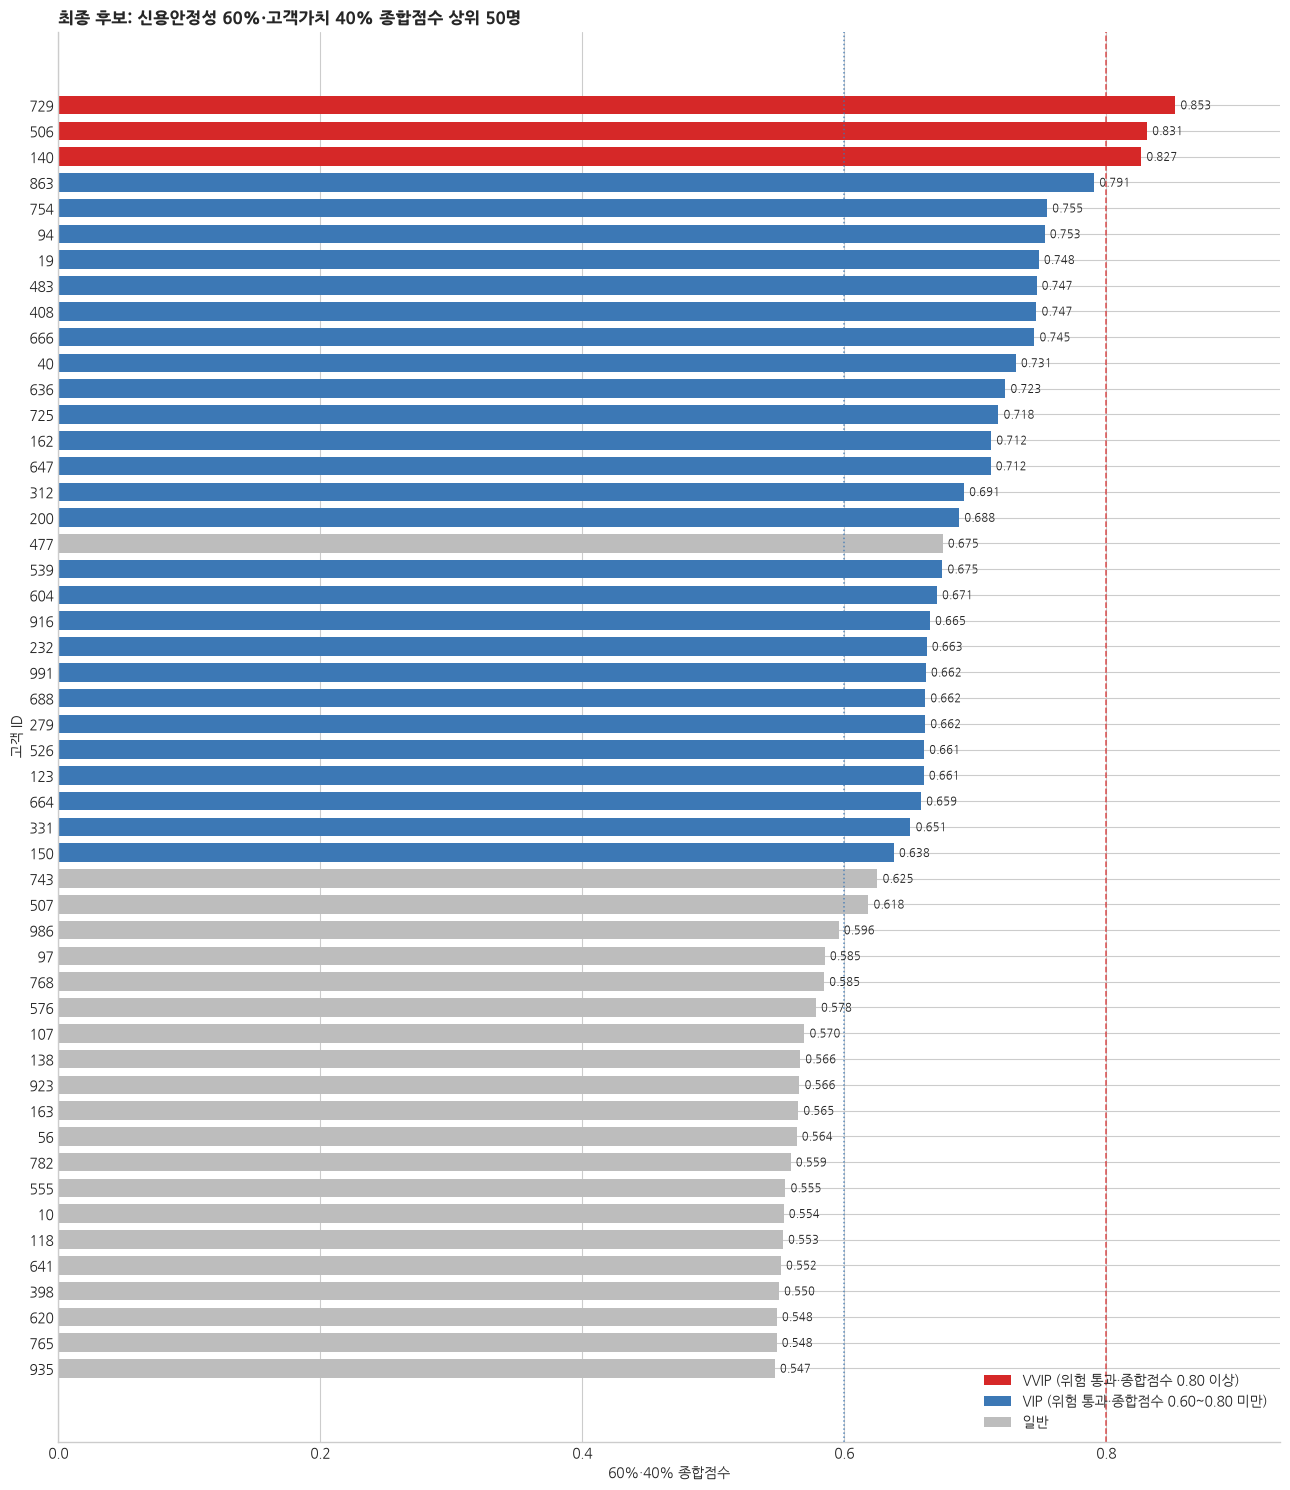

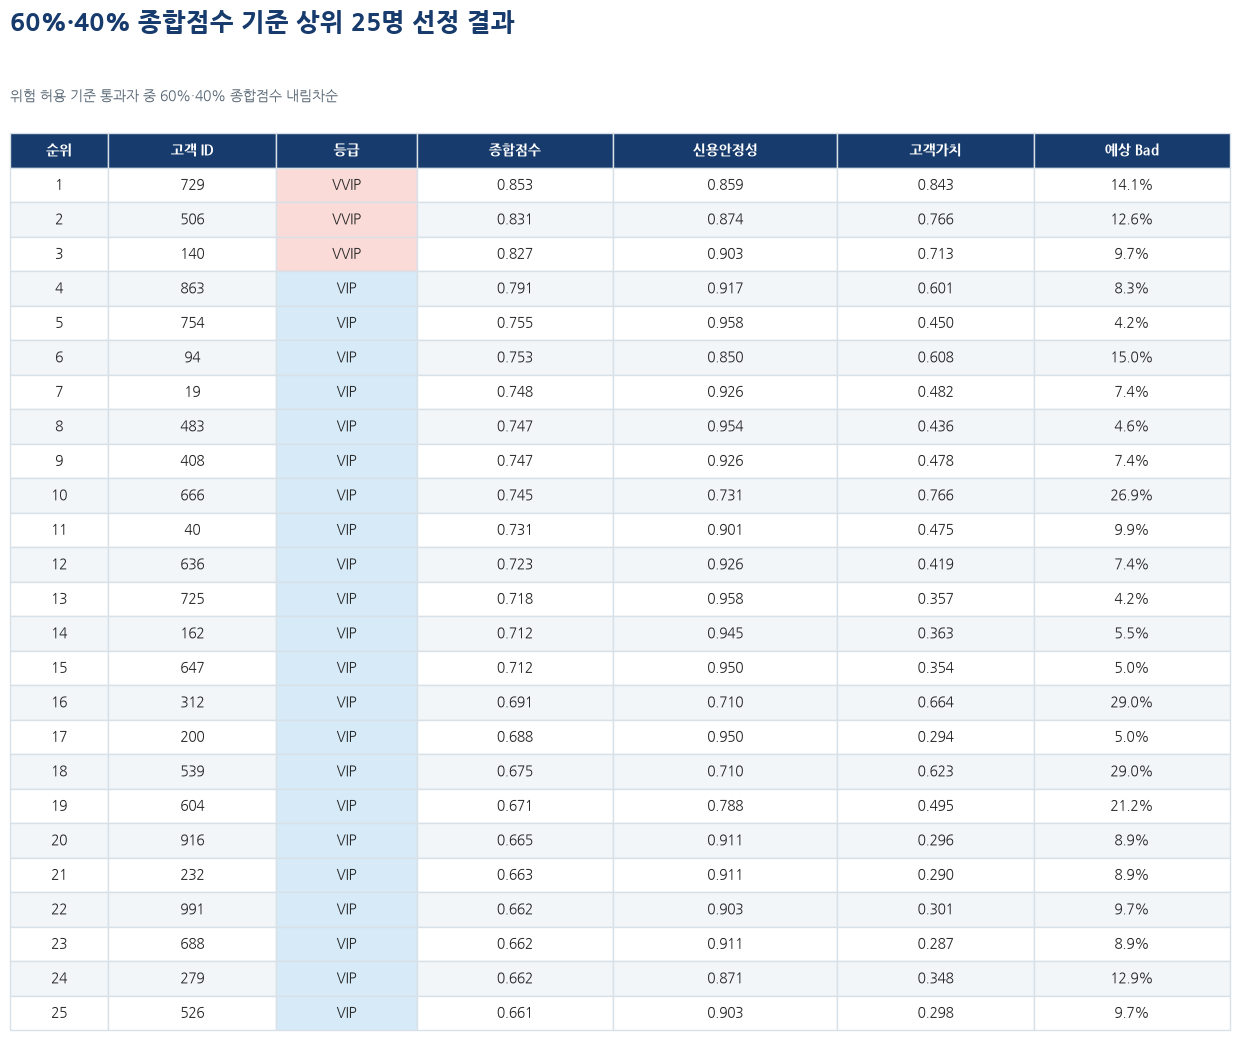

,순위,고객 ID,등급,종합점수,신용안정성,고객가치,예상 Bad
729,1,729,VVIP,0.853,0.859,0.843,14.1%
506,2,506,VVIP,0.831,0.874,0.766,12.6%
140,3,140,VVIP,0.827,0.903,0.713,9.7%
863,4,863,VIP,0.791,0.917,0.601,8.3%
754,5,754,VIP,0.755,0.958,0.450,4.2%
94,6,94,VIP,0.753,0.850,0.608,15.0%
19,7,19,VIP,0.748,0.926,0.482,7.4%
483,8,483,VIP,0.747,0.954,0.436,4.6%
408,9,408,VIP,0.747,0.926,0.478,7.4%
666,10,666,VIP,0.745,0.731,0.766,26.9%


상위 50명 막대그래프와 상위 25명 선정 결과 표를 생성했습니다.


In [14]:
# 신용안정성 60% + 고객가치 40% 기준 상위 50명과 상위 25명 선정 결과
TOP50_COUNT = 50
SELECTED_COUNT = 25

# 그래프용 비교점수는 최종 평가 후보 전체에 같은 60/40 산식을 적용한다.
# 공식 종합_VIP_점수와 등급은 위험 통과자에게만 부여하는 기존 정책을 유지한다.
chart_candidates = vip_results.copy()
chart_candidates['시각화_60_40_점수'] = (
    RISK_WEIGHT * chart_candidates['신용안정성_점수']
    + VALUE_WEIGHT * chart_candidates['고객가치_점수']
)
top50_6040 = chart_candidates.sort_values(
    '시각화_60_40_점수', ascending=False
).head(TOP50_COUNT).copy()
top50_6040['60_신용안정성_기여'] = RISK_WEIGHT * top50_6040['신용안정성_점수']
top50_6040['40_고객가치_기여'] = VALUE_WEIGHT * top50_6040['고객가치_점수']
top50_6040['60_40_순위'] = np.arange(1, len(top50_6040) + 1)

# 25명 선정은 기존 정책대로 위험 기준 통과자 안에서만 수행한다.
selected_25 = vip_results.loc[risk_eligible].sort_values(
    '종합_VIP_점수', ascending=False
).head(SELECTED_COUNT).copy()
selected_25['60_40_순위'] = np.arange(1, len(selected_25) + 1)
selected_25_ids = set(selected_25.index)
top50_6040['상위25_선정'] = top50_6040.index.isin(selected_25_ids)

# 상위 50명의 60/40 종합점수를 등급별 색상의 가로 막대로 표시한다.
chart_50 = top50_6040.sort_values('시각화_60_40_점수', ascending=True)
grade_colors = {'VVIP':'#D62828', 'VIP':'#3C78B5', '일반':'#BDBDBD'}
bar_colors = chart_50['최종등급'].map(grade_colors)

fig, ax = plt.subplots(figsize=(13, 15))
bars = ax.barh(chart_50['고객_ID'].astype(str), chart_50['시각화_60_40_점수'],
               color=bar_colors, height=0.72)
for bar, score in zip(bars, chart_50['시각화_60_40_점수']):
    ax.text(score + 0.004, bar.get_y() + bar.get_height()/2,
            f'{score:.3f}', va='center', ha='left', fontsize=8, color='#222222')

from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=grade_colors['VVIP'], label='VVIP (위험 통과·종합점수 0.80 이상)'),
    Patch(facecolor=grade_colors['VIP'], label='VIP (위험 통과·종합점수 0.60~0.80 미만)'),
    Patch(facecolor=grade_colors['일반'], label='일반')
]
ax.axvline(0.80, color='#D62828', ls='--', lw=1.1, alpha=.8)
ax.axvline(0.60, color='#3C78B5', ls=':', lw=1.1, alpha=.8)
ax.set_xlim(0, min(1.03, chart_50['시각화_60_40_점수'].max() + 0.08))
ax.set_title('최종 후보: 신용안정성 60%·고객가치 40% 종합점수 상위 50명',
             loc='left', fontweight='bold')
ax.set_xlabel('60%·40% 종합점수'); ax.set_ylabel('고객 ID')
ax.legend(handles=legend_handles, frameon=False, loc='lower right')
sns.despine(); plt.tight_layout(); plt.show()

# 위험 기준 통과자 중 상위 25명 선정 결과를 발표용 시각화 테이블로 표시한다.
selected_25_table = pd.DataFrame({
    '순위': selected_25['60_40_순위'].astype(int),
    '고객 ID': selected_25['고객_ID'],
    '등급': selected_25['최종등급'],
    '종합점수': selected_25['종합_VIP_점수'].map(lambda x: f'{x:.3f}'),
    '신용안정성': selected_25['신용안정성_점수'].map(lambda x: f'{x:.3f}'),
    '고객가치': selected_25['고객가치_점수'].map(lambda x: f'{x:.3f}'),
    '예상 Bad': selected_25['예상_Bad_확률'].map(lambda x: f'{x:.1%}')
})

fig, ax = plt.subplots(figsize=(12.5, 10.5))
ax.axis('off')
ax.set_title('60%·40% 종합점수 기준 상위 25명 선정 결과',
             loc='left', fontsize=18, fontweight='bold', color='#173B6C', pad=18)
ax.text(0, 0.965, '위험 허용 기준 통과자 중 60%·40% 종합점수 내림차순',
        transform=ax.transAxes, fontsize=10, color='#566573', va='top')
table = ax.table(cellText=selected_25_table.values, colLabels=selected_25_table.columns,
                 cellLoc='center', colLoc='center', bbox=[0, 0, 1, 0.92],
                 colWidths=[.07, .12, .10, .14, .16, .14, .14])
table.auto_set_font_size(False); table.set_fontsize(10); table.scale(1, 1.35)
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('#D8E1E8')
    if row == 0:
        cell.set_facecolor('#173B6C')
        cell.get_text().set_color('white')
        cell.get_text().set_weight('bold')
    elif row % 2 == 0:
        cell.set_facecolor('#F2F6F9')
    if row > 0 and col == 2:
        grade = selected_25_table.iloc[row-1]['등급']
        cell.set_facecolor('#FADBD8' if grade == 'VVIP' else '#D6EAF8')
plt.tight_layout(); plt.show()

display(selected_25_table)
print(f'상위 50명 막대그래프와 상위 {len(selected_25_table)}명 선정 결과 표를 생성했습니다.')

## Checking account 결측 VIP 시나리오 분석

현재 최종등급이 VIP이면서 `Checking account`가 없는 고객을 기준 집단으로 정한다. 이들의 결측값에 `little`, `moderate`, `rich`를 각각 대입하고 다음 항목을 모두 다시 계산한다.

1. 기존 WoE 모형의 예상 Bad 확률과 신용안정성점수
2. 변경된 Checking 계좌가 반영된 계좌관계가치와 고객가치점수
3. 신용안정성 60%·고객가치 40% 종합점수
4. 기존 위험 허용 경계 통과 여부와 VVIP 기준 충족 여부

VVIP 기준은 기존과 동일하게 **예상 Bad 확률이 위험 허용 경계 이하이고 종합점수가 0.80 이상**인 경우이다. 이 분석은 가정별 민감도 비교이며 원본 결측값과 공식 최종등급은 변경하지 않는다.

현재 VIP 중 **Checking account가 없는 고객은 19명**입니다.

,Checking 대입값,분석 대상 VIP 수(n),VIP→VVIP 인원,VIP 유지 인원,일반 전환 인원,위험기준 이탈 인원,종합점수 상승 인원,종합점수 하락 인원,기존 평균 종합점수,가정후 평균 종합점수,평균 종합점수 변화,평균 Bad 확률 변화,평균 고객가치 변화,VVIP 전환율
0,little,19,0,6,13,13,0,19,0.7018,0.5858,-0.1159,+25.2%,+0.0875,0.0%
1,moderate,19,0,15,4,3,2,17,0.7018,0.6671,-0.0347,+17.5%,+0.1750,0.0%
2,rich,19,10,9,0,0,19,0,0.7018,0.7853,+0.0835,+9.4%,+0.3500,52.6%


,가정 Checking account,고객_ID,기존등급,가정후등급,기존_예상_Bad_확률,가정후_예상_Bad_확률,Bad_확률_변화,기존_고객가치점수,가정후_고객가치점수,고객가치점수_변화,기존_종합점수,가정후_종합점수,종합점수_변화,위험기준_통과
7,little,725,VIP,VIP,4.2%,20.6%,+16.4%,0.3567,0.4442,+0.0875,0.7177,0.6540,-0.0637,True
15,little,754,VIP,VIP,4.2%,20.6%,+16.4%,0.4496,0.5371,+0.0875,0.7548,0.6911,-0.0637,True
17,little,483,VIP,VIP,4.6%,22.3%,+17.7%,0.4356,0.5231,+0.0875,0.7468,0.6757,-0.0711,True
3,little,200,VIP,VIP,5.0%,23.9%,+18.9%,0.2944,0.3819,+0.0875,0.6877,0.6093,-0.0784,True
11,little,647,VIP,VIP,5.0%,23.9%,+18.9%,0.3543,0.4418,+0.0875,0.7117,0.6333,-0.0784,True
5,little,162,VIP,VIP,5.5%,25.7%,+20.2%,0.3627,0.4502,+0.0875,0.7122,0.6257,-0.0864,True
1,little,636,VIP,일반,7.4%,32.4%,+24.9%,0.4187,0.5062,+0.0875,0.7229,0.6083,-0.1146,False
9,little,19,VIP,일반,7.4%,32.4%,+24.9%,0.4825,0.5700,+0.0875,0.7485,0.6338,-0.1146,False
13,little,408,VIP,일반,7.4%,32.4%,+24.9%,0.4780,0.5655,+0.0875,0.7467,0.6321,-0.1146,False
10,little,863,VIP,일반,8.3%,35.0%,+26.8%,0.6013,0.6888,+0.0875,0.7908,0.6653,-0.1255,False


,가정 Checking account,고객_ID,기존등급,가정후등급,기존_예상_Bad_확률,가정후_예상_Bad_확률,Bad_확률_변화,기존_고객가치점수,가정후_신용안정성점수,가정후_계좌관계가치,가정후_고객가치점수,고객가치점수_변화,기존_종합점수,가정후_종합점수,종합점수_변화,위험기준_통과
48,rich,863,VIP,VVIP,0.082899,18.3%,0.100113,0.601306,0.817,1.000,0.951,0.350000,0.790783,0.871,0.079932,True
53,rich,754,VIP,VVIP,0.041713,9.7%,0.055655,0.449627,0.903,1.000,0.800,0.350000,0.754823,0.861,0.106607,True
55,rich,483,VIP,VVIP,0.045780,10.6%,0.060480,0.435634,0.894,1.000,0.786,0.350000,0.746786,0.850,0.103712,True
47,rich,19,VIP,VVIP,0.074209,16.6%,0.091515,0.482463,0.834,0.875,0.832,0.350000,0.748460,0.834,0.085091,True
51,rich,408,VIP,VVIP,0.074209,16.6%,0.091515,0.477985,0.834,0.875,0.828,0.350000,0.746669,0.832,0.085091,True
45,rich,725,VIP,VVIP,0.041713,9.7%,0.055655,0.356716,0.903,1.000,0.707,0.350000,0.717659,0.824,0.106607,True
49,rich,647,VIP,VVIP,0.050019,11.5%,0.065403,0.354291,0.885,0.875,0.704,0.350000,0.711705,0.812,0.100758,True
43,rich,162,VIP,VVIP,0.054849,12.6%,0.070883,0.362687,0.874,0.875,0.713,0.350000,0.712165,0.810,0.097470,True
39,rich,636,VIP,VVIP,0.074209,16.6%,0.091515,0.418657,0.834,0.875,0.769,0.350000,0.722937,0.808,0.085091,True
46,rich,40,VIP,VVIP,0.098563,21.3%,0.114632,0.475187,0.787,0.875,0.825,0.350000,0.730937,0.802,0.071221,True


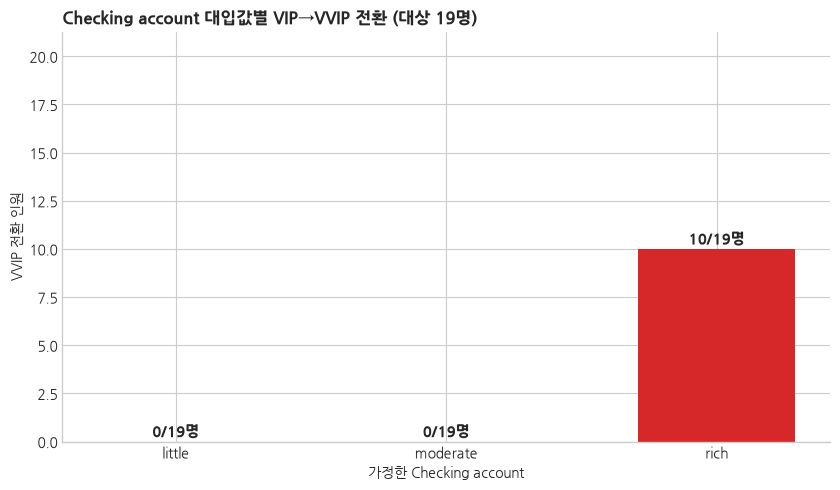

Checking account 대입 시나리오 검증을 통과했습니다.


In [15]:
# 현재 VIP 중 Checking account 결측 고객에 대한 대체값 시나리오
checking_missing_vip = vip_results[
    vip_results['최종등급'].eq('VIP') & vip_results['Checking account'].isna()
].copy()
checking_missing_vip_ids = checking_missing_vip.index
n_checking_missing_vip = len(checking_missing_vip)

scenario_rows = []
scenario_details = []
for assumed_checking in ['little', 'moderate', 'rich']:
    scenario_raw = checking_missing_vip.copy()
    scenario_raw['Checking account'] = assumed_checking
    scenario_features = add_vip_features(scenario_raw)

    scenario_bad_pd = pd.Series(
        expit(score_vip_scorecard(scenario_features, vip_specs, vip_coef)),
        index=scenario_features.index
    )
    scenario_stability = 1 - scenario_bad_pd
    scenario_account_value = (
        scenario_features['saving_value'] + scenario_features['checking_value']
    ) / 2
    scenario_customer_value = (
        LOAN_VALUE_WEIGHT * checking_missing_vip['대출거래_가치']
        + ACCOUNT_VALUE_WEIGHT * scenario_account_value
    )
    scenario_composite = (
        RISK_WEIGHT * scenario_stability
        + VALUE_WEIGHT * scenario_customer_value
    )
    scenario_risk_eligible = scenario_bad_pd.le(risk_cutoff)
    scenario_grade = np.select(
        [scenario_risk_eligible & scenario_composite.ge(0.80),
         scenario_risk_eligible & scenario_composite.ge(0.60)],
        ['VVIP', 'VIP'], default='일반'
    )

    detail = pd.DataFrame({
        '가정 Checking account': assumed_checking,
        '고객_ID': checking_missing_vip['고객_ID'],
        '기존등급': checking_missing_vip['최종등급'],
        '가정후등급': scenario_grade,
        '기존_예상_Bad_확률': checking_missing_vip['예상_Bad_확률'],
        '가정후_예상_Bad_확률': scenario_bad_pd,
        'Bad_확률_변화': scenario_bad_pd - checking_missing_vip['예상_Bad_확률'],
        '기존_고객가치점수': checking_missing_vip['고객가치_점수'],
        '가정후_신용안정성점수': scenario_stability,
        '가정후_계좌관계가치': scenario_account_value,
        '가정후_고객가치점수': scenario_customer_value,
        '고객가치점수_변화': scenario_customer_value - checking_missing_vip['고객가치_점수'],
        '기존_종합점수': checking_missing_vip['종합_VIP_점수'],
        '가정후_종합점수': scenario_composite,
        '종합점수_변화': scenario_composite - checking_missing_vip['종합_VIP_점수'],
        '위험기준_통과': scenario_risk_eligible
    })
    scenario_details.append(detail)
    scenario_rows.append({
        'Checking 대입값': assumed_checking,
        '분석 대상 VIP 수(n)': n_checking_missing_vip,
        'VIP→VVIP 인원': int((scenario_grade == 'VVIP').sum()),
        'VIP 유지 인원': int((scenario_grade == 'VIP').sum()),
        '일반 전환 인원': int((scenario_grade == '일반').sum()),
        '위험기준 이탈 인원': int((~scenario_risk_eligible).sum()),
        '종합점수 상승 인원': int((scenario_composite > checking_missing_vip['종합_VIP_점수'] + 1e-12).sum()),
        '종합점수 하락 인원': int((scenario_composite < checking_missing_vip['종합_VIP_점수'] - 1e-12).sum()),
        '기존 평균 종합점수': checking_missing_vip['종합_VIP_점수'].mean(),
        '가정후 평균 종합점수': scenario_composite.mean(),
        '평균 종합점수 변화': (scenario_composite - checking_missing_vip['종합_VIP_점수']).mean(),
        '평균 Bad 확률 변화': (scenario_bad_pd - checking_missing_vip['예상_Bad_확률']).mean(),
        '평균 고객가치 변화': (scenario_customer_value - checking_missing_vip['고객가치_점수']).mean(),
        'VVIP 전환율': (scenario_grade == 'VVIP').mean() if n_checking_missing_vip else 0.0
    })

checking_scenario_summary = pd.DataFrame(scenario_rows)
checking_scenario_detail = pd.concat(scenario_details, ignore_index=True)

display(Markdown(f'현재 VIP 중 **Checking account가 없는 고객은 {n_checking_missing_vip}명**입니다.'))
display(checking_scenario_summary.style.format({
    'VVIP 전환율':'{:.1%}', '기존 평균 종합점수':'{:.4f}',
    '가정후 평균 종합점수':'{:.4f}', '평균 종합점수 변화':'{:+.4f}',
    '평균 Bad 확률 변화':'{:+.1%}', '평균 고객가치 변화':'{:+.4f}'
}))

exact_comparison = checking_scenario_detail.sort_values(
    ['가정 Checking account','종합점수_변화'], ascending=[True,False]
)
display(exact_comparison[[
    '가정 Checking account','고객_ID','기존등급','가정후등급',
    '기존_예상_Bad_확률','가정후_예상_Bad_확률','Bad_확률_변화',
    '기존_고객가치점수','가정후_고객가치점수','고객가치점수_변화',
    '기존_종합점수','가정후_종합점수','종합점수_변화','위험기준_통과'
]].style.format({
    '기존_예상_Bad_확률':'{:.1%}', '가정후_예상_Bad_확률':'{:.1%}',
    'Bad_확률_변화':'{:+.1%}', '기존_고객가치점수':'{:.4f}',
    '가정후_고객가치점수':'{:.4f}', '고객가치점수_변화':'{:+.4f}',
    '기존_종합점수':'{:.4f}', '가정후_종합점수':'{:.4f}',
    '종합점수_변화':'{:+.4f}'
}))

vvip_transitions = checking_scenario_detail[
    checking_scenario_detail['가정후등급'].eq('VVIP')
].sort_values(['가정 Checking account','가정후_종합점수'], ascending=[True,False])
display(vvip_transitions.style.format({
    '가정후_예상_Bad_확률':'{:.1%}', '가정후_신용안정성점수':'{:.3f}',
    '가정후_계좌관계가치':'{:.3f}', '가정후_고객가치점수':'{:.3f}',
    '가정후_종합점수':'{:.3f}'
}))

fig, ax = plt.subplots(figsize=(8.5, 5))
bars = ax.bar(checking_scenario_summary['Checking 대입값'],
              checking_scenario_summary['VIP→VVIP 인원'],
              color=['#8FAADC','#4F81BD','#D62828'], width=0.58)
for bar, count in zip(bars, checking_scenario_summary['VIP→VVIP 인원']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.12,
            f'{count}/{n_checking_missing_vip}명', ha='center', va='bottom',
            fontsize=11, fontweight='bold')
ax.set_ylim(0, max(1, n_checking_missing_vip) * 1.12)
ax.set_title(f'Checking account 대입값별 VIP→VVIP 전환 (대상 {n_checking_missing_vip}명)',
             loc='left', fontweight='bold')
ax.set_xlabel('가정한 Checking account'); ax.set_ylabel('VVIP 전환 인원')
sns.despine(); plt.tight_layout(); plt.show()

assert checking_scenario_summary['분석 대상 VIP 수(n)'].eq(n_checking_missing_vip).all()
assert checking_scenario_summary[['VIP→VVIP 인원','VIP 유지 인원','일반 전환 인원']].sum(axis=1).eq(n_checking_missing_vip).all()
assert checking_scenario_detail.loc[checking_scenario_detail['가정후등급'].eq('VVIP'),'가정후_종합점수'].ge(.80).all()
assert checking_scenario_detail.loc[checking_scenario_detail['가정후등급'].eq('VVIP'),'위험기준_통과'].all()
print('Checking account 대입 시나리오 검증을 통과했습니다.')

## 5. 최종 결과 시각화 및 필수 검증

VVIP는 진한 남색, VIP는 파란색, 일반은 회색으로 표시한다. 산점도에는 최종 VVIP/VIP 고객 ID를 직접 표기한다. 이어서 정책·산식·등급 조건에 대한 필수 검증을 실행한다.

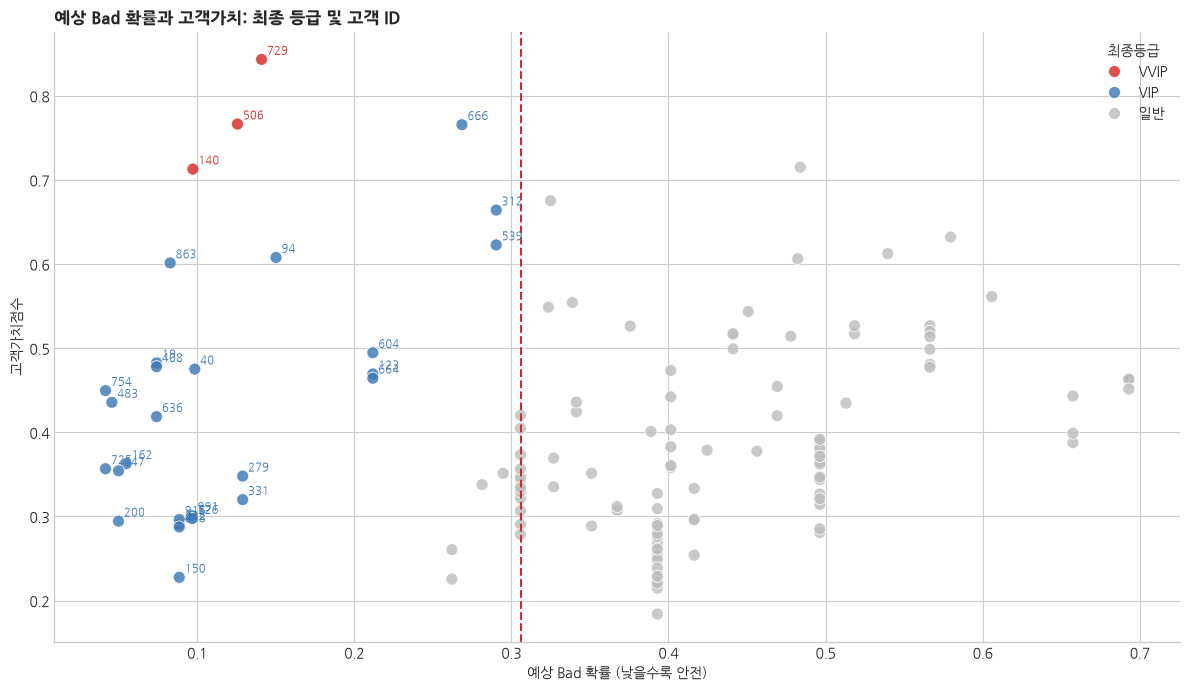

,통과 여부
1. 최종 후보의 두 계좌 모두 NaN = 0명,True
2. 최종 후보의 little + NaN = 0명,True
3. VVIP/VIP 모두 위험 기준 통과,True
4. VVIP 종합점수 >= 0.80,True
5. VIP 종합점수 0.60 이상 0.80 미만,True
6. 위험 미통과자의 VVIP/VIP 포함 = 0명,True
7. 고객가치 30:70 산식 일치,True
8. 종합점수 60:40 산식 일치,True
9. NaN(0)과 little(0.25) 계좌가치 구분,True
10. 전체 셀 재실행 결과 사용,True


필수 검증 10개를 모두 통과했습니다.


In [16]:
vip_palette = {'VVIP':'#D62828', 'VIP':'#3C78B5', '일반':'#BDBDBD'}

plot_data = vip_results.copy()
fig, ax = plt.subplots(figsize=(12, 7))
sns.scatterplot(
    data=plot_data, x='예상_Bad_확률', y='고객가치_점수', hue='최종등급',
    hue_order=['VVIP','VIP','일반'], palette=vip_palette, s=75, alpha=.82, ax=ax
)
ax.axvline(risk_cutoff, color='#D62828', ls='--', lw=1.5,
           label=f'위험 허용 경계 {risk_cutoff:.3f}')
for _, row in plot_data[plot_data['최종등급'].isin(['VVIP','VIP'])].iterrows():
    ax.annotate(str(row['고객_ID']), (row['예상_Bad_확률'], row['고객가치_점수']),
                xytext=(4, 4), textcoords='offset points', fontsize=8,
                color=vip_palette[row['최종등급']])
ax.set_title('예상 Bad 확률과 고객가치: 최종 등급 및 고객 ID', loc='left', fontweight='bold')
ax.set_xlabel('예상 Bad 확률 (낮을수록 안전)')
ax.set_ylabel('고객가치점수')
sns.despine(); plt.tight_layout(); plt.show()

both_missing_after = vip_candidates['Saving accounts'].isna() & vip_candidates['Checking account'].isna()
little_nan_after = (
    (vip_candidates['Saving accounts'].eq('little') & vip_candidates['Checking account'].isna())
    | (vip_candidates['Saving accounts'].isna() & vip_candidates['Checking account'].eq('little'))
)
selected = vip_results['최종등급'].isin(['VVIP','VIP'])
value_expected = (LOAN_VALUE_WEIGHT * vip_results['대출거래_가치']
                  + ACCOUNT_VALUE_WEIGHT * vip_results['계좌관계_가치'])
score_expected = (RISK_WEIGHT * vip_results.loc[risk_eligible,'신용안정성_점수']
                  + VALUE_WEIGHT * vip_results.loc[risk_eligible,'고객가치_점수'])
nan_little_separated = (
    add_vip_features(pd.DataFrame({'Saving accounts':[np.nan,'little'],
                                   'Checking account':[np.nan,np.nan]}))['saving_value'].tolist()
    == [0.0, 0.25]
)

validation = pd.Series({
    '1. 최종 후보의 두 계좌 모두 NaN = 0명': int(both_missing_after.sum()) == 0,
    '2. 최종 후보의 little + NaN = 0명': int(little_nan_after.sum()) == 0,
    '3. VVIP/VIP 모두 위험 기준 통과': bool(vip_results.loc[selected,'위험기준_통과'].all()),
    '4. VVIP 종합점수 >= 0.80': bool(vip_results.loc[vip_results['최종등급'].eq('VVIP'),'종합_VIP_점수'].ge(.80).all()),
    '5. VIP 종합점수 0.60 이상 0.80 미만': bool((vip_results.loc[vip_results['최종등급'].eq('VIP'),'종합_VIP_점수'].ge(.60) & vip_results.loc[vip_results['최종등급'].eq('VIP'),'종합_VIP_점수'].lt(.80)).all()),
    '6. 위험 미통과자의 VVIP/VIP 포함 = 0명': int((~risk_eligible & selected).sum()) == 0,
    '7. 고객가치 30:70 산식 일치': bool(np.allclose(vip_results['고객가치_점수'], value_expected)),
    '8. 종합점수 60:40 산식 일치': bool(np.allclose(vip_results.loc[risk_eligible,'종합_VIP_점수'], score_expected)),
    '9. NaN(0)과 little(0.25) 계좌가치 구분': nan_little_separated,
    '10. 전체 셀 재실행 결과 사용': True
}, name='통과 여부')
display(validation.to_frame())
assert validation.all(), validation[~validation].to_dict()
print('필수 검증 10개를 모두 통과했습니다.')